      eps  delta                            method            kind  either  point_above  nonlocal_  mean_loss_diff  worst_regret  auroc_gain
0   0.005  0.010                            Pooled  no certificate     5.2         68.8        NaN          0.0029        0.0245      0.0005
1   0.005  0.010                            Pooled       certified     0.0          0.0       17.0          0.0000        0.0012      0.0002
2   0.005  0.010                     AFL (floor 0)  no certificate    79.2        117.4        NaN          0.0201        0.0780     -0.0565
3   0.005  0.010                     AFL (floor 0)       certified     0.0          0.0        1.0          0.0000        0.0009     -0.0000
4   0.005  0.010                   AFL (floor 0.5)  no certificate    27.4         95.2        NaN          0.0093        0.0346     -0.0322
5   0.005  0.010                   AFL (floor 0.5)       certified     0.0          0.0        7.4          0.0001        0.0017     -0.0002
6   0.005  0.

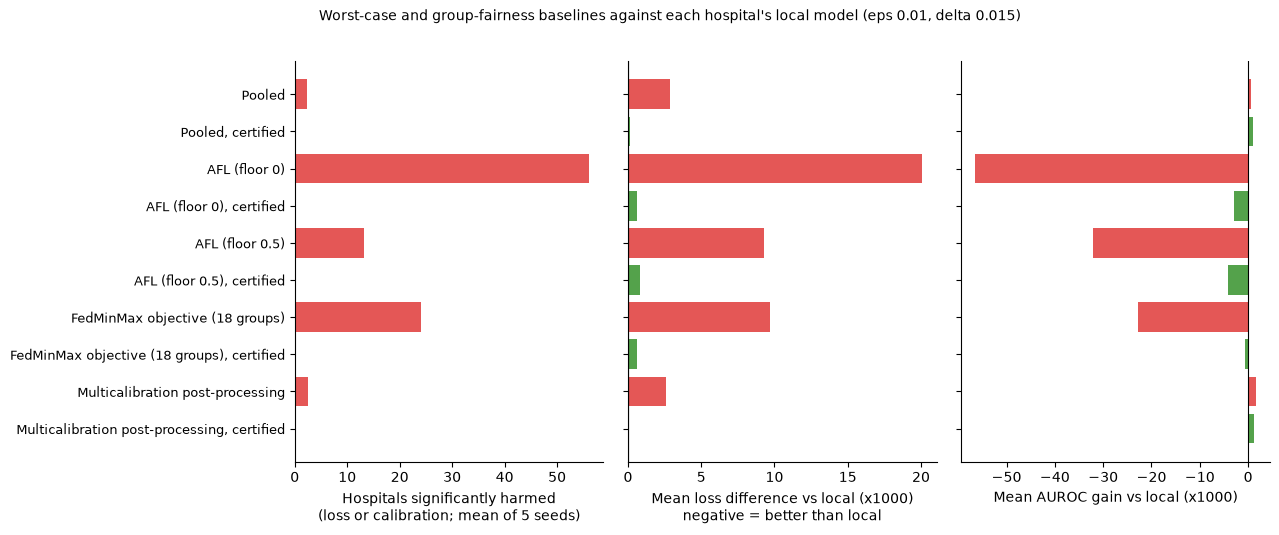

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]; HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
D = {s: pd.read_csv(f"../outputs/tables/more_baselines_seed{s}.csv").copy() for s in seeds}
SRC = ["pool", "afl0", "afl0.5", "fedminmax", "multicalib"]
NAME = {"pool": "Pooled", "afl0": "AFL (floor 0)", "afl0.5": "AFL (floor 0.5)",
        "fedminmax": "FedMinMax objective (18 groups)", "multicalib": "Multicalibration post-processing"}

def lm(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows = []
for eps, delta in HEAD:
    for src in SRC:
        for kind, pre in [("no certificate", src), ("certified", f"cert_{src}_e{eps}_d{delta}")]:
            out = []
            for s in seeds:
                r = D[s]; l = lm(r, pre, eps); c = r[f"{pre}__gaplb"].values > delta
                out.append(dict(either=(l | c).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                                mean_loss_diff=r[f"{pre}__diff"].mean(), worst_regret=r[f"{pre}__diff"].max(),
                                auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean()))
            rows.append({"eps": eps, "delta": delta, "method": NAME[src], "kind": kind, **pd.DataFrame(out).mean().to_dict()})
T = pd.DataFrame(rows); T.to_csv("../outputs/tables/T_more_baselines.csv", index=False); print(T.round(4).to_string())

t = T[(T.eps == 0.01) & (T.delta == 0.015)].reset_index(drop=True)
t["label"] = t.method + np.where(t.kind == "certified", ", certified", "")
col = np.where(t.kind == "certified", "#54A24B", "#E45756")
yy = np.arange(len(t))[::-1]
fig, ax = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
ax[0].barh(yy, t.either, color=col); ax[0].set_xlabel("Hospitals significantly harmed\n(loss or calibration; mean of 5 seeds)")
ax[1].barh(yy, 1000 * t.mean_loss_diff, color=col); ax[1].axvline(0, c="k", lw=0.8); ax[1].set_xlabel("Mean loss difference vs local (x1000)\nnegative = better than local")
ax[2].barh(yy, 1000 * t.auroc_gain, color=col); ax[2].axvline(0, c="k", lw=0.8); ax[2].set_xlabel("Mean AUROC gain vs local (x1000)")
ax[0].set_yticks(yy); ax[0].set_yticklabels(t.label, fontsize=9)
fig.suptitle("Worst-case and group-fairness baselines against each hospital's local model (eps 0.01, delta 0.015)", fontsize=10)
plt.subplots_adjust(wspace=0.08, left=0.25)
plt.savefig("../outputs/figures/fig25_more_baselines.png", dpi=300); plt.savefig("../outputs/figures/fig25_more_baselines.pdf"); plt.show()